# 📊 Analyse univariée et bivariée

> ✍️ **Notebook dirigé** · complétez les cellules marquées ✍️ À VOUS.

**Jour 1 · 10h00** · Exercice

*Analyse exploratoire et interprétation métier*

**Objectifs**
- Nettoyer le minimum avant d'analyser, en le justifiant
- Décrire les variables clés une par une
- Tester vos hypothèses sur le lien entre deux variables

**Maison Lumen — Soualiho KAMAGATÉ et Julien FOURNIER**

In [1]:
import os, sys, subprocess, importlib.util
for paquet in ["pandas", "numpy", "matplotlib", "seaborn", "scipy", "statsmodels", "fairlearn", "gdown"]:
    if importlib.util.find_spec(paquet) is None:
        subprocess.check_call([sys.executable,"-m","pip","install","-q",paquet])
CONFIG_ID="1bW5RsToUHc-7pGiyHS_1B2OYkAFsrv3r"
if not os.path.exists("config_projet.py"):
    import gdown
    gdown.download(id=CONFIG_ID,output="config_projet.py",quiet=True)
print("✅ Configuration prête")

In [2]:
# Choisissez votre secteur : "commerce", "banque" ou "hotellerie"
SECTEUR = "commerce"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from config_projet import charger, reference, nettoyage_minimal

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
brut, cfg = charger(SECTEUR)
print(cfg["nom"], "·", brut.shape[0], "lignes,", brut.shape[1], "colonnes")
from pathlib import Path
from IPython.display import display, Markdown
evenement=pd.Timestamp(cfg["evenement"][0])
sensibles=cfg["sensibles"]


Maison Lumen · 24224 lignes, 16 colonnes


In [3]:
from scipy import stats

## 1. Le nettoyage minimal
Retirez les doublons exacts, les âges inférieurs à 18 ans et les montants négatifs. Combien de lignes perdez-vous ?

In [4]:
df=nettoyage_minimal(brut,cfg)
df["region"]=df.region.fillna("inconnu")
df["apres"]=df.date_commande.ge(evenement).astype(int)
df["periode"]=np.where(df.apres.eq(1),"Après refonte","Avant refonte")
print(len(brut),"→",len(df),"; lignes retirées :",len(brut)-len(df))
print("Doublons exacts :",brut.duplicated().sum(),"; avoirs négatifs après dédoublonnage :",brut.drop_duplicates().montant_eur.lt(0).sum())

24224 → 24089 ; lignes retirées : 135
Doublons exacts : 121 ; avoirs négatifs après dédoublonnage : 14


**Justification**

Les 121 doublons exacts sont retirés pour éviter de compter une commande deux fois. Les 14 avoirs négatifs sont exclus conformément au nettoyage demandé. Le total étudié ne correspond donc pas à un CA comptable net des avoirs. Les commandes élevées et les achats distincts d’un même client sont conservés. Les régions absentes sont regroupées sous « inconnu ».

## 2. La variable de chiffre d'affaires
Statistiques descriptives, histogramme (échelle log si besoin) et boîte à moustaches. La moyenne représente-t-elle bien un client typique ?

,Montant par commande (€)
count,24089.000000
mean,77.668233
std,119.668229
min,9.050000
25%,34.690000
50%,48.970000
75%,75.270000
max,5406.730000


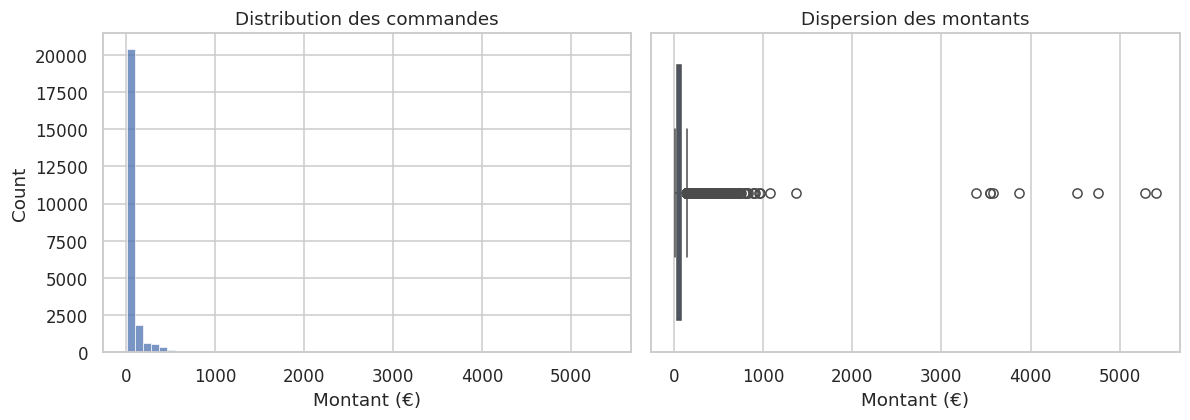

Le total atteint **1,870,950 €**. Une commande vaut en moyenne **77.67 €**, contre une médiane de **48.97 €**. Les grandes commandes tirent la moyenne vers le haut ; la médiane décrit mieux un panier courant.

In [5]:
display(df.montant_eur.describe().to_frame("Montant par commande (€)"))
fig, ax = plt.subplots(1,2,figsize=(11,4))
sns.histplot(df.montant_eur,bins=60,ax=ax[0]); ax[0].set(xlabel="Montant (€)",title="Distribution des commandes")
sns.boxplot(x=df.montant_eur,ax=ax[1]);ax[1].set(xlabel="Montant (€)",title="Dispersion des montants")
plt.tight_layout();plt.show()
display(Markdown(f"Le total atteint **{df.montant_eur.sum():,.0f} €**. Une commande vaut en moyenne **{df.montant_eur.mean():.2f} €**, contre une médiane de **{df.montant_eur.median():.2f} €**. Les grandes commandes tirent la moyenne vers le haut ; la médiane décrit mieux un panier courant."))

## 3. Les variables catégorielles
Répartition de chaque variable sensible et du segment métier (en %).

In [6]:
for col in sensibles + ["canal","categorie"]:
    display(pd.DataFrame({"Effectif":df[col].value_counts(dropna=False),"Part (%)":df[col].value_counts(normalize=True,dropna=False)*100}))

,Effectif,Part (%)
tranche_age,,
25-34,7123,29.569513
35-44,5954,24.716676
45-54,4110,17.061729
18-24,3396,14.097721
55-64,2040,8.468596
65+,1466,6.085765


,Effectif,Part (%)
genre,,
F,15105,62.704969
H,8984,37.295031


,Effectif,Part (%)
region,,
Île-de-France,7571,31.429283
Sud-Est,4844,20.108763
Ouest,4292,17.817261
Nord-Est,4010,16.646602
Sud-Ouest,2781,11.544688
Outre-mer,353,1.465399
inconnu,238,0.988003


,Effectif,Part (%)
canal,,
magasin,12059,50.060193
web,9324,38.706464
app,2706,11.233343


,Effectif,Part (%)
categorie,,
Déco,7163,29.735564
Textile,6564,27.248952
Luminaire,4824,20.025738
Cuisine,3581,14.865706
Mobilier,1957,8.124040


## 4. Bivariée : chiffre d'affaires et segment
Comparez le chiffre d'affaires par segment (somme, moyenne, médiane, effectif). La différence est-elle significative ? Utilisez Kruskal-Wallis.

In [7]:
display(df.groupby("canal").montant_eur.agg(["size","sum","mean","median"]))
kw=stats.kruskal(*[g.montant_eur for _,g in df.groupby("canal")])
print(f"Kruskal-Wallis : H={kw.statistic:.2f}, p={kw.pvalue:.3g}")

print("Le test compare les distributions des montants entre canaux. Les commandes répétées rendent sa p-valeur exploratoire ; il ne prouve pas un effet du canal.")

,size,sum,mean,median
canal,,,,
app,2706,219820.96,81.234649,50.005
magasin,12059,924308.74,76.648871,48.620
web,9324,726820.37,77.951563,49.355


Kruskal-Wallis : H=4.94, p=0.0847
Le test compare les distributions des montants entre canaux. Les commandes répétées rendent sa p-valeur exploratoire ; il ne prouve pas un effet du canal.


## 5. Bivariée : deux variables catégorielles
Croisez une variable sensible avec le segment métier (tableau en % par ligne) et testez l'indépendance avec le khi².

In [8]:
tab=pd.crosstab(df.tranche_age,df.canal)
chi,pval,ddl,att=stats.chi2_contingency(tab)
v=np.sqrt(chi/(tab.to_numpy().sum()*min(tab.shape[0]-1,tab.shape[1]-1)))
display(pd.crosstab(df.tranche_age,df.canal,normalize="index").mul(100).round(1))
print(f"Khi² : p={pval:.3g} ; V de Cramér={v:.3f} ; minimum attendu={att.min():.1f}")
print("Un lien entre âge et canal peut expliquer une partie des écarts de ciblage. Le V de Cramér aide à juger son ampleur ; le khi² seul ne mesure pas une discrimination.")

canal,app,magasin,web
tranche_age,,,
18-24,12.0,48.0,40.0
25-34,11.9,47.0,41.1
35-44,12.4,45.9,41.8
45-54,11.7,46.7,41.7
55-64,6.9,68.6,24.5
65+,6.5,70.5,23.0


Khi² : p=8.58e-127 ; V de Cramér=0.113 ; minimum attendu=164.7
Un lien entre âge et canal peut expliquer une partie des écarts de ciblage. Le V de Cramér aide à juger son ampleur ; le khi² seul ne mesure pas une discrimination.


## 6. Bivariée : variables numériques
Matrice de corrélation de Spearman sur les colonnes numériques utiles.

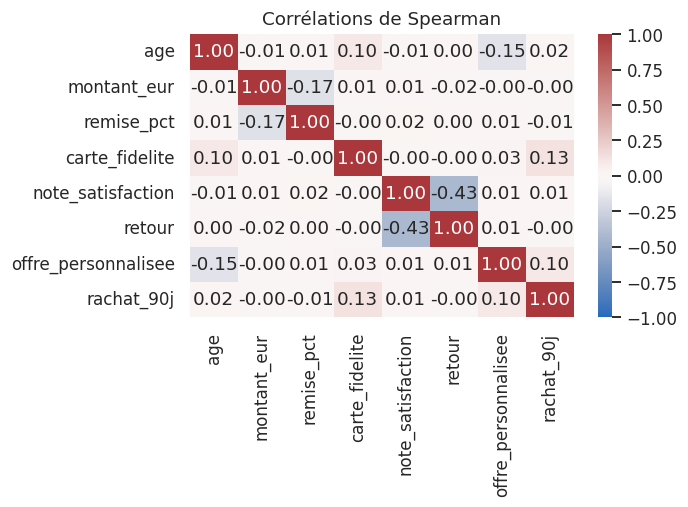

La satisfaction et les retours présentent le lien négatif le plus marqué dans cette matrice. Les notes ne concernent que les répondants. Les autres corrélations ne prouvent pas un effet causal.


In [9]:
cols=["age","montant_eur","remise_pct","carte_fidelite","note_satisfaction","retour","offre_personnalisee","rachat_90j"]
sns.heatmap(df[cols].corr(method="spearman"),center=0,vmin=-1,vmax=1,cmap="vlag",annot=True,fmt=".2f")
plt.title("Corrélations de Spearman");plt.tight_layout();plt.show()
print("La satisfaction et les retours présentent le lien négatif le plus marqué dans cette matrice. Les notes ne concernent que les répondants. Les autres corrélations ne prouvent pas un effet causal.")

## 7. Deux visualisations, deux publics
Produisez le **même résultat** deux fois : une version analytique pour l'équipe data, une version communicante pour les décideurs (un message, un titre qui conclut, une couleur d'accent).

taux     n
tranche_age periode                      
18-24       Après refonte  0.475676  2220
            Avant refonte  0.482143  1176
25-34       Après refonte  0.488515  4571
            Avant refonte  0.475313  2552
35-44       Après refonte  0.386611  3854
            Avant refonte  0.381905  2100
45-54       Après refonte  0.405083  2597
            Avant refonte  0.395902  1513
55-64       Après refonte  0.256950  1331
            Avant refonte  0.229901   709
65+         Après refonte  0.179296   937
            Avant refonte  0.164461   529

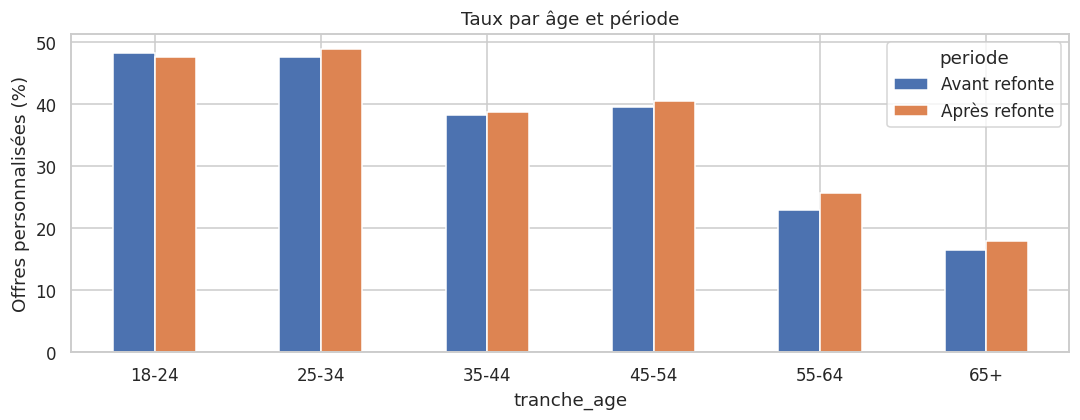

In [10]:
t=df.groupby(["tranche_age","periode"]).offre_personnalisee.agg(taux="mean",n="size")
display(t)
r=t.taux.unstack().reindex(columns=["Avant refonte","Après refonte"])*100
ax=r.plot.bar(figsize=(10,4),rot=0);ax.set(ylabel="Offres personnalisées (%)",title="Taux par âge et période")
plt.tight_layout();plt.show()


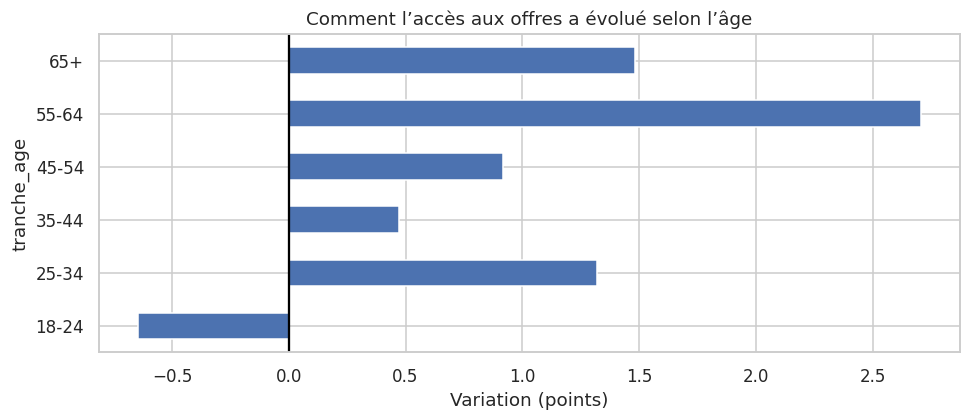

Les évolutions par âge restent modestes par rapport aux écarts de niveau entre groupes. La refonte ne semble pas avoir supprimé ces écarts.


In [11]:
ax=(r["Après refonte"]-r["Avant refonte"]).plot.barh(figsize=(9,4))
ax.axvline(0,color="black");ax.set(xlabel="Variation (points)",title="Comment l’accès aux offres a évolué selon l’âge")
plt.tight_layout();plt.show()
print("Les évolutions par âge restent modestes par rapport aux écarts de niveau entre groupes. La refonte ne semble pas avoir supprimé ces écarts.")

In [12]:
# Erreurs standards regroupées par client pour tenir compte des commandes répétées.
import statsmodels.formula.api as smf
mensuel=df.assign(mois=df.date_commande.dt.to_period("M")).groupby("mois").montant_eur.sum()
# Avril 2024 est exclu : il mélange avant et après la refonte.
a=mensuel.loc[mensuel.index < pd.Period("2024-04")]
b=mensuel.loc[mensuel.index > pd.Period("2024-04")]
w=stats.ttest_ind(b,a,equal_var=False)
display(Markdown(f"**H1 :** le CA mensuel moyen passe de **{a.mean():,.0f} €** à **{b.mean():,.0f} €**, soit **{(b.mean()/a.mean()-1)*100:+.1f} %** (Welch, p={w.pvalue:.3g}). L’hypothèse est {'soutenue sur cette comparaison brute' if b.mean()>a.mean() and w.pvalue<.05 else 'non confirmée par ce test'}. La saisonnalité reste à contrôler."))
m=df.assign(mois=df.date_commande.dt.to_period("M")).groupby(["mois","canal"]).montant_eur.sum().unstack(fill_value=0)
compar=pd.DataFrame({"Avant (€/mois)":m.loc[m.index<pd.Period("2024-04")].mean(),"Après (€/mois)":m.loc[m.index>pd.Period("2024-04")].mean()})
compar["Hausse (€/mois)"]=compar.iloc[:,1]-compar.iloc[:,0]
display(compar.round(2))
display(Markdown(f"**H2 :** la plus forte hausse mensuelle en euros concerne **{compar['Hausse (€/mois)'].idxmax()}**. {'Le classement va dans le sens de H2.' if compar['Hausse (€/mois)'].idxmax()=='app' else 'Le classement ne confirme pas H2.'} Il s’agit d’une décomposition descriptive, pas d’un test causal du lancement de l’application."))
modele=smf.ols("offre_personnalisee ~ C(tranche_age)",data=df).fit(cov_type="cluster",cov_kwds={"groups":df.client_id})
display(modele.summary().tables[1])
terms=[i for i,x in enumerate(modele.params.index) if x.startswith("C(tranche_age)")]
R=np.eye(len(modele.params))[terms]
p_age=float(modele.wald_test(R,scalar=True).pvalue)
display(df.groupby("tranche_age").offre_personnalisee.agg(["mean","size"]))
display(Markdown(f"**H3 :** le test global des écarts d’âge donne **p={p_age:.3g}**, avec des erreurs standards regroupées par client. L’hypothèse est {'soutenue' if p_age<.05 else 'non soutenue'} au seuil de 5 %. "))

**H1 :** le CA mensuel moyen passe de **42,153 €** à **59,493 €**, soit **+41.1 %** (Welch, p=7.82e-05). L’hypothèse est soutenue sur cette comparaison brute. La saisonnalité reste à contrôler.

,Avant (€/mois),Après (€/mois),Hausse (€/mois)
canal,,,
app,1912.34,9307.94,7395.60
magasin,26419.52,25131.01,-1288.51
web,13821.34,25053.64,11232.30


**H2 :** la plus forte hausse mensuelle en euros concerne **web**. Le classement ne confirme pas H2. Il s’agit d’une décomposition descriptive, pas d’un test causal du lancement de l’application.

,coef,std err,z,P>|z|,[0.025,0.975]
Intercept,0.4779,0.009,56.023,0.000,0.461,0.495
C(tranche_age)[T.25-34],0.0059,0.010,0.569,0.570,-0.014,0.026
C(tranche_age)[T.35-44],-0.0930,0.011,-8.764,0.000,-0.114,-0.072
C(tranche_age)[T.45-54],-0.0762,0.012,-6.567,0.000,-0.099,-0.053
C(tranche_age)[T.55-64],-0.2304,0.013,-17.650,0.000,-0.256,-0.205
C(tranche_age)[T.65+],-0.3040,0.013,-22.568,0.000,-0.330,-0.278


,mean,size
tranche_age,,
18-24,0.477915,3396
25-34,0.483785,7123
35-44,0.384951,5954
45-54,0.401703,4110
55-64,0.247549,2040
65+,0.173943,1466


**H3 :** le test global des écarts d’âge donne **p=9.91e-215**, avec des erreurs standards regroupées par client. L’hypothèse est soutenue au seuil de 5 %. 

**Vos hypothèses après cette étape** : confirmées, infirmées, à creuser ?

H1 est soutenue sur la comparaison brute du CA mensuel, mais la saisonnalité reste à examiner. H2 n’est pas confirmée sur l’ensemble des mois complets avant/après : le web présente la plus forte hausse en euros. H3 est soutenue : le taux d’offre diffère selon l’âge ; le rôle du canal sera étudié dans le notebook 04. 

💾 **Versionnez** : *Fichier › Enregistrer une copie dans GitHub*, message de commit : « Univarié et bivarié : verdict sur H1 à H3 »